In [15]:
%load_ext autoreload
%autoreload 2
%reset -f
%matplotlib widget

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [16]:
import sys
from pathlib import Path
import pandas as pd
from lib.config import PEAKMIN_CONFIG_PARAMS_DEFAULT, FLOWRATE_CONFIG_PARAMS_DEFAULT
r2 = Path.cwd()  # keep notebook kernel cwd on Challenge_SystemHealthAlarm/r2
sys.path.insert(0, str(r2.parents[2] / "packages"))
sys.path.insert(0, str(r2))

from lib.Detector.FlowrateDetector import *
from lib.Detector.PeakMinDetector import *
from lib.Detector.FaultDetector import *
import matplotlib.pyplot as plt

In [17]:
import numpy as np

case_id = "ENBW_01"
data = pd.read_parquet("faulty_data/faulty_data_labeled.parquet")
case_df = (
    data.loc[data["CaseId"] == case_id]
    .sort_values("StartDateTime")
    .reset_index(drop=True)
)

In [18]:
flowrate_detector = FlowRateDetector()
flowrate_detector.load_data(args={'resource': case_df})
flowrate_detector.load_config(args={'resource': pd.DataFrame([FLOWRATE_CONFIG_PARAMS_DEFAULT])})
flowrate_detector.run_detector(write_back=False)

349
Running detector FlowRateDetector from index 0 to 349


In [19]:
peak_detector = PeakMinDetector()
peak_detector.load_data(args={'resource': case_df})
# In-memory test only: CustomPPM uses N_win=30, N_curr=5 (DB ConfigParams unchanged).
peak_detector.load_config(args={'resource': pd.DataFrame([PEAKMIN_CONFIG_PARAMS_DEFAULT])})
peak_detector.run_detector(write_back=False)

349
Running detector PeakMinDetector from index 0 to 349


In [20]:
detector_list = [flowrate_detector, peak_detector]
fault_detector = FaultDetector()
fault_detector.load_data(args={'resource': detector_list})
fault_detector.load_config(args={'resource': pd.DataFrame([FAULT_CONFIG_PARAMS_DEFAULT])})
fault_detector.sandbox_data.columns


349


/home/sandbox/personal-repos/Challenges/Challenge_SystemHealthAlarm/r2/lib/Detector/FaultDetector.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp_data.rename(columns={'LastUpdate': detector.name + 'LastUpdate'}, inplace=True)


Index(['SurveyId', 'SurveyorUnit', 'RawDurationMinutes', 'StartDateTime',
       'EndDateTime', 'PeakCount', 'AverageFlowRate', 'PeakMinutes', 'CaseId',
       'faulty', 'FlowrateS', 'FlowrateSpred', 'FlowrateDx', 'FlowrateDelta',
       'FlowrateAlpha', 'FlowrateBeta', 'FlowrateI', 'FlowRateC', 'FlowrateH',
       'FlowRateFlag', 'FlowRateNStep', 'FlowRateDetectorLastUpdate', 'PeakS',
       'PeakC', 'PeakI', 'PeakH', 'PeakMinDetectorLastUpdate', 'FaultH',
       'LastUpdate'],
      dtype='object')

In [21]:
fault_detector.run_detector(write_back=False)


Running detector FaultDetector from index 0 to 349


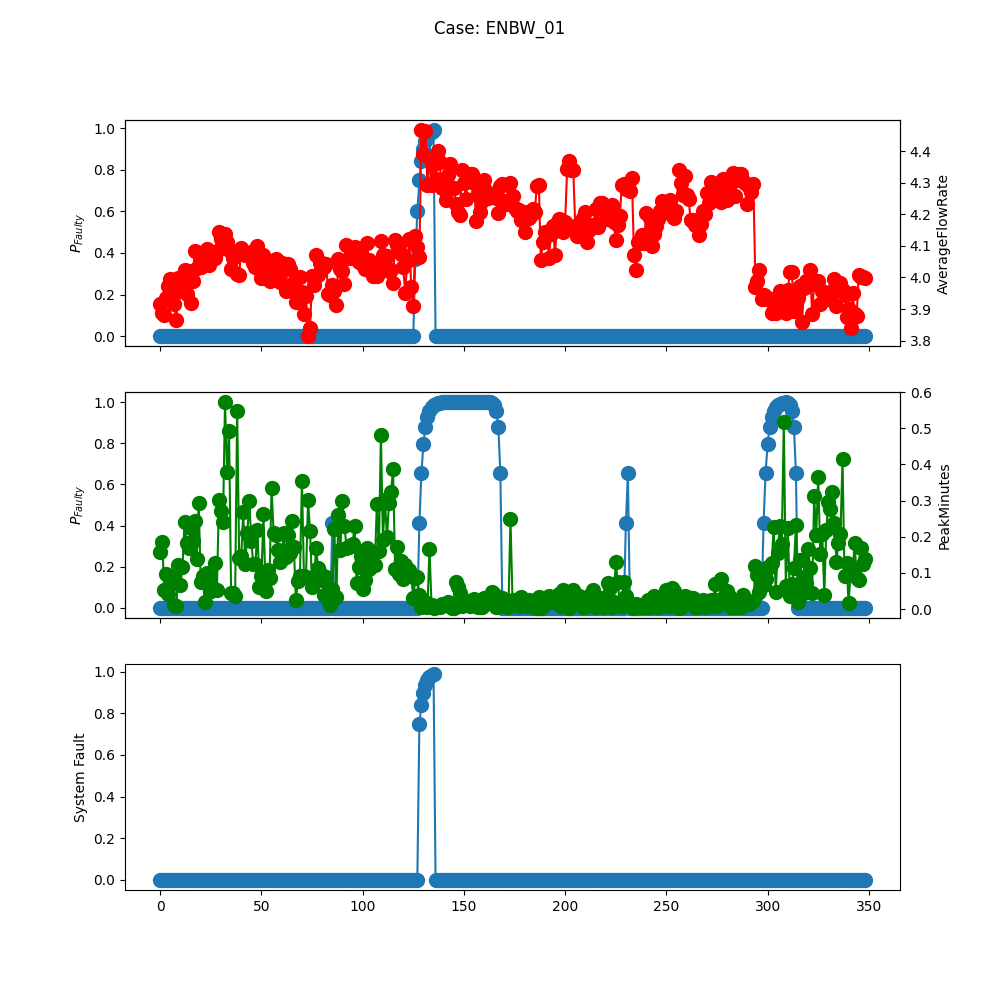

In [22]:
fig,ax = plt.subplots(3,1, sharex=True, figsize=(10,10))
fig.suptitle(f'Case: {case_id}')
ax[0].plot(flowrate_detector.sandbox_data["FlowrateH"], marker='o', markersize=10)
ax[0].set_ylabel("FlowrateH")
ax00 =ax[0].twinx()
ax00.plot(flowrate_detector.sandbox_data["AverageFlowRate"], marker='o', markersize=10, color='red')
ax[0].set_ylabel("$P_{Faulty}$")
ax00.set_ylabel("AverageFlowRate")
ax[1].plot(peak_detector.sandbox_data["PeakH"], marker='o', markersize=10)
ax10 = ax[1].twinx()
ax10.plot(peak_detector.sandbox_data["PeakMinutes"], marker='o', markersize=10, color='green')
ax[1].set_ylabel("$P_{Faulty}$")
ax10.set_ylabel("PeakMinutes")
ax[2].plot(fault_detector.sandbox_data["FaultH"], marker='o', markersize=10)
ax[2].set_ylabel("System Fault")
plt.show()